# Committor Model: 2D Brownian Z Potential, Staple Paths, Longer Fit

Continues the NPNEq fit of the staple run `sim_istarz_br_g10` (overdamped Langevin, γ = 10, kT = 0.05, dt = 0.002, Z potential `sjoelbak_angle(Lx=0.3, angle=45)`), with the same data and settings as the original fit by `load_tis_data_cupy.py`, only for longer. Optionally adds the ridge-normal coordinate y + x as a CV.

**Why:** the original fit (10000 iterations) put the plateau beyond the 45° ridge 0.05–0.07 too high, confirmed by shooting with the toytis engine (`docs/npneq_tis_notes.md`, `figures/z_brownian/`). Its `zqs_z` was still falling (3.68 → 3.23 over the last 6000 iterations) and the stopped Z_q sat at about −3 at the longest lags for q below the plateau. Two questions: does it converge with more iterations, and does a CV aligned with the ridge (y + x) remove the overshoot?

**Data:** the original fit's `figures/istarz_br_g10/committor.npz`: 29975 accepted paths (3000 per ensemble), each cut at its first frame past M, 20.8M frames, MC path weights (`rejections`), and the fitted q. It can also be re-read from the run with `tis_data.prepare_data` (section 2).

**Boundaries:** `y <= 0.05` (A) and `y >= 0.85` (B), the first and last interfaces. The order parameter y is the first position of the phase point; x is the transverse position.

## 1. Imports

In [4]:
import argparse
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
import cupy as cp
from scipy.interpolate import RegularGridInterpolator

# Plot styling
plt.rc('font', size=10)
plt.rc('axes', titlesize=14)
plt.rc('axes', labelsize=14)
plt.rc('xtick', labelsize=12)
plt.rc('ytick', labelsize=12)
plt.rc('legend', fontsize=12)

# Custom optimal-RC / committor package (CuPy) and the path-data loader of the examples
REPO = '/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs'
sys.path.insert(0, f'{REPO}/optimalrcs-cupy/')
sys.path.insert(0, f'{REPO}/examples/')
import optimalrcs, metrics, plots
import tis_data
FIG = f'{REPO}/examples/figures'

## 2. Data Loading

By default the frames and the fitted q of the original fit are loaded from `committor.npz`, so the data and their order are exactly those of that fit. With `REREAD = True` the paths are read again from the simulation with the original fit's settings (all paths in the folders, which hold the 3000-path subset; rejection weights; cut at M; no mirrored pieces).

Each path is one segment, so the independence group of a frame is its segment (`group_traj = i_traj`).

In [5]:
FIT_NPZ = f'{FIG}/istarz_br_g10/committor.npz'
REREAD = False
TIS_DIR = '/home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istarz_br_g10'

if REREAD:
    parser = argparse.ArgumentParser()
    tis_data.add_data_arguments(parser)
    args = parser.parse_args([TIS_DIR])            # defaults of the original fit
    data = tis_data.prepare_data(args)
    X_all, lam, i_traj, t_traj = data.X_all, data.lam, data.i_traj, data.t_traj
    path_weights, boundary0, boundary1 = data.path_weights, data.boundary0, data.boundary1
    r_saved = np.load(FIT_NPZ)['r'] if os.path.exists(FIT_NPZ) else None
    if r_saved is not None and len(r_saved) != len(lam):
        r_saved = None                             # a different data set: start from scratch
else:
    d = np.load(FIT_NPZ)
    X_all, lam, i_traj, t_traj = d['X_all'], d['lam'], d['i_traj'], d['t_traj']
    path_weights, boundary0, boundary1 = d['path_weights'], d['boundary0'], d['boundary1']
    r_saved = d['r']
group_traj = i_traj                                # one segment per path (no mirrored pieces)
y_pos, x_pos = X_all[:, 0], X_all[:, 1]
lambda_a, lambda_b = 0.05, 0.85
print(f'{len(lam)} frames in {len(np.unique(i_traj))} paths; frames in A {boundary0.sum()}, in B {boundary1.sum()}')

20848384 frames in 29975 paths; frames in A 7597, in B 1738


## 3. Train Committor (Non-Parametric), Continued

Same settings as the original fit (`load_tis_data_cupy.py` defaults with `--lazy-basis`). The original run set no random seeds, so the CV draws differ; a seed is set here for reproducibility.

With `CONTINUE = True` the fit starts from the saved q (10000 iterations done), otherwise from scratch. With `ADD_DIAG = True` the CVs are (y, x, y + x): y + x is the coordinate normal to the ridge, so a single update can follow the 45° step.

Paths stop at their first A/B frame; `set_fixed_traj_length_trap` treats those ends as traps so the Z_q-based metrics keep the windows that run into A or B. Convergence: `zqs_z` (worst |stopped Z_q / standard error| over q and lags) about 2 or less; for paths cut at t\* the stopped Z_q of the committor is 0 (notes §8.1).

**Parameters:**
| Parameter | Value | Description |
|-----------|-------|-------------|
| `envelope_scale` | 0.01 | RC envelope width (library default, as in the original fit) |
| `gamma` | 0.1 | Regularization (scales the step; does not change the fixed point) |
| `ny` | 6 | Polynomial degree |
| `max_iter` | 30000 | Iterations in this run (~0.4 s each on 20.8M frames) |
| `lazy_basis` | True | Basis in fused GPU kernels (less memory, same result) |
| `CONTINUE` | True | Start from the saved q |
| `ADD_DIAG` | False | Add y + x as a CV |

**Seeds and warm-up** (`seed_runs.run_seeds`, shared with the other notebooks): the fit is repeated for every seed in `SEEDS` (the seed sets which CV and envelope centre each iteration draws). The first `WARMUP_ITER` iterations of every seed can use their own envelope (`WARMUP_ENVELOPE`), gamma (`WARMUP_GAMMA`) and CV (`WARMUP_CV`: `None` random, otherwise the index of the CV to use); then `ENVELOPE` and `GAMMA` take over (`WARMUP_ITER = 0`: no warm-up). After the warm-up and every `CHUNK` iterations the plots in `PLOTS` are shown here and saved to `<OUT>/seed<s>/it<N>_<plot>.png`, with a progress line. The objects of earlier seeds are freed; `q` is the last seed's fit and `results[seed]['r']` every seed's RC.

**Committor map per chunk** (`seed_runs.committor_map`): after the warm-up and every chunk, the mean q per (y, x) bin next to the exact committor and fit − exact (with its RMS over the bins where 0.05 < q_exact < 0.95), on the effective potential, as in section 4; saved as `it<N>_q_y_x.png`.

#=500, dr2=407.827, zqs_z=43.5379, sdzqs=60.0779, |dx|=0.32443, time=34.5892
#=1000, dr2=351.758, zqs_z=22.6299, sdzqs=50.02, |dx|=0.0334299, time=69.1407
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/nb_brownian_staple/yx/seed0/it1000 ---


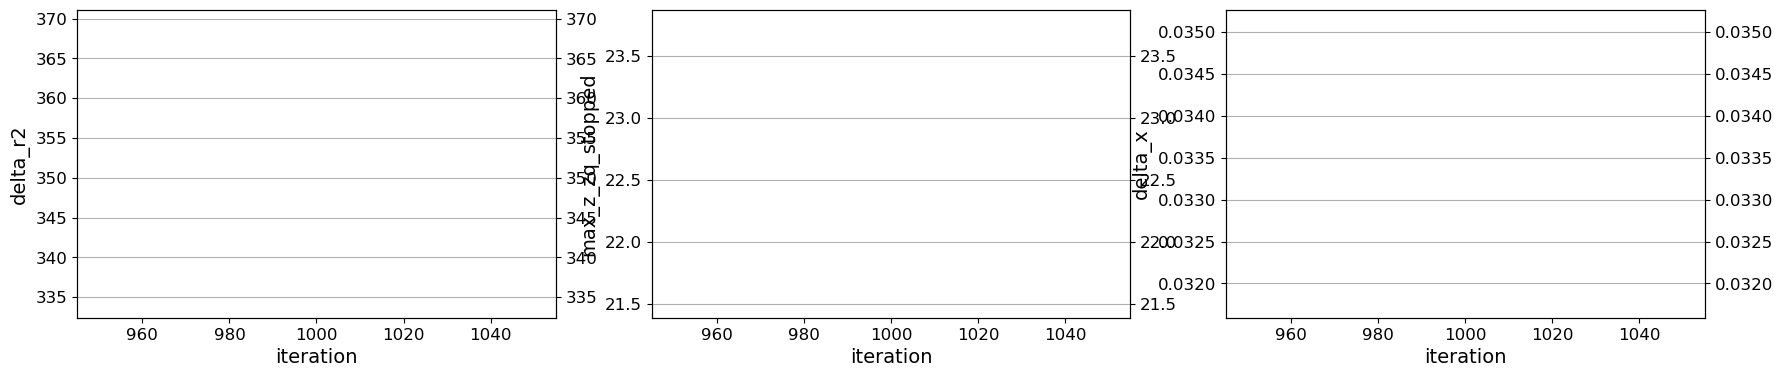

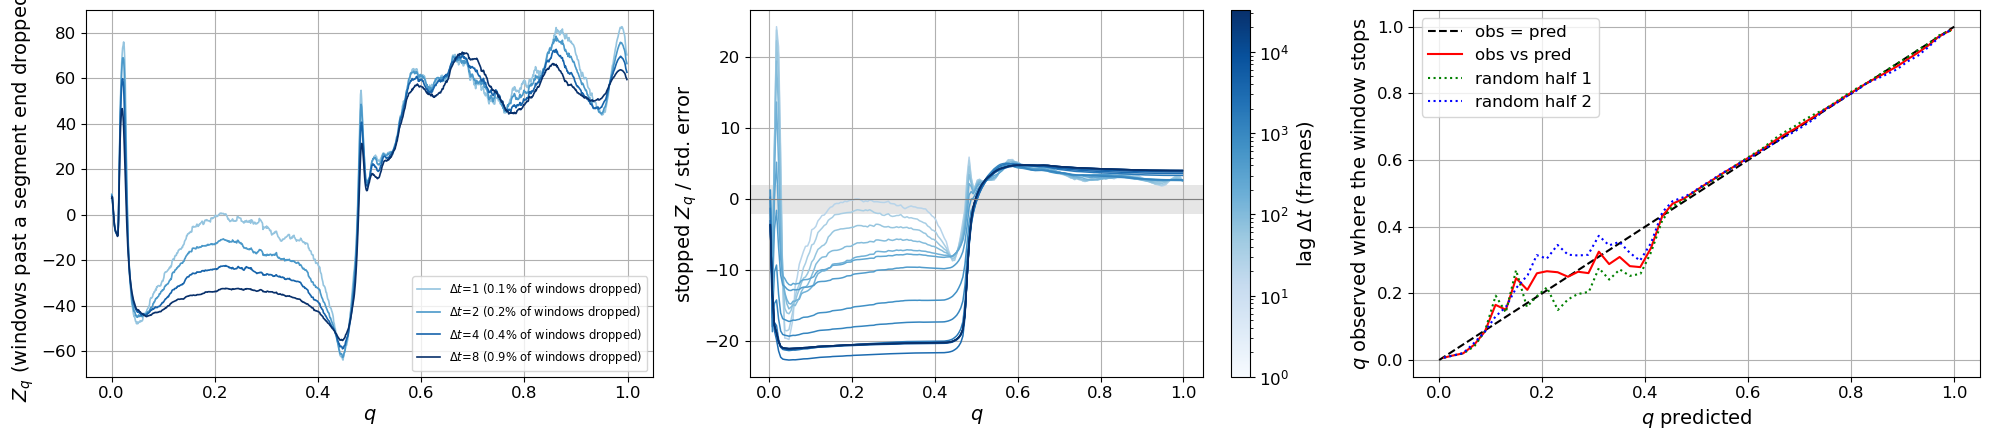

seed 0, 1000 iterations (warm-up: envelope 1, gamma 0.1) | fit/shooting at plateau points: 0.501/0.639 0.541/0.664 0.575/0.698 0.648/0.747
#=1500, dr2=290.649, zqs_z=9.05424, sdzqs=43.0664, |dx|=0.0178245, time=34.4726
#=2000, dr2=267.387, zqs_z=5.77156, sdzqs=38.0087, |dx|=0.0163989, time=68.9816
#=2500, dr2=247.669, zqs_z=4.77721, sdzqs=31.9676, |dx|=0.0154432, time=103.485
#=3000, dr2=231.616, zqs_z=4.37045, sdzqs=27.1177, |dx|=0.0135849, time=137.998
#=3500, dr2=219.98, zqs_z=3.72356, sdzqs=23.4007, |dx|=0.0106279, time=172.539
#=4000, dr2=210.002, zqs_z=3.54381, sdzqs=20.1781, |dx|=0.00971909, time=230.923

Training interrupted at iteration 4160; keeping the RC of the last completed update.
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/nb_brownian_staple/yx/seed0/it6000 ---


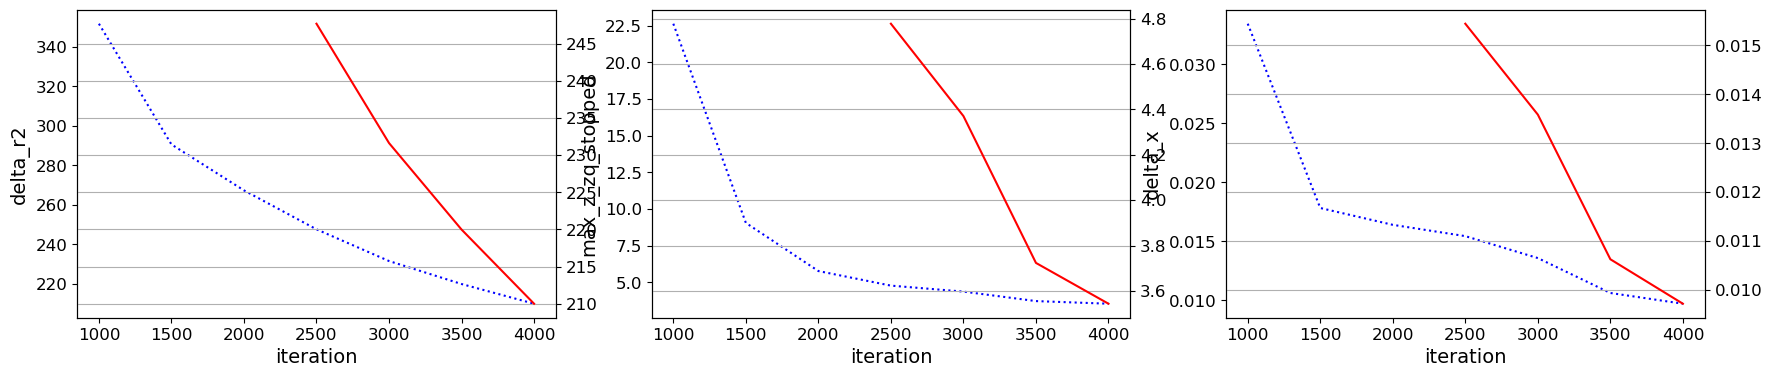

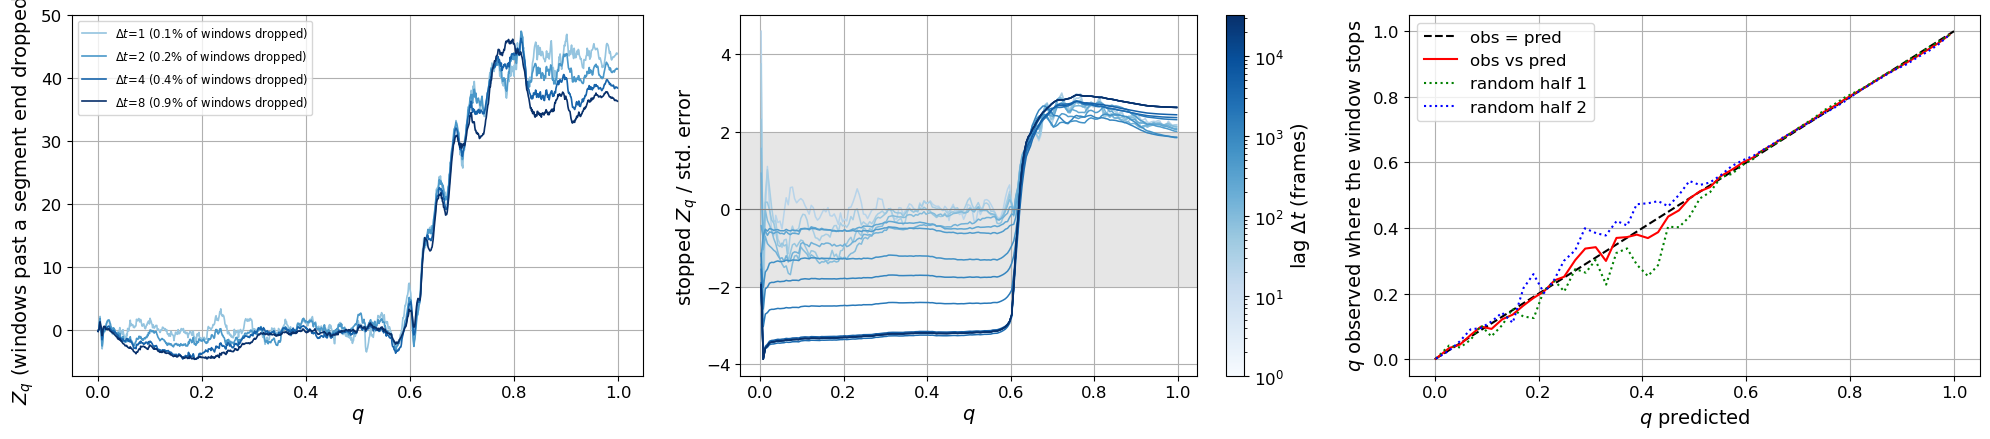

seed 0, 6000 iterations (main: envelope 0.01, gamma 0.1) | fit/shooting at plateau points: 0.630/0.639 0.670/0.664 0.686/0.698 0.743/0.747
#=4500, dr2=201.091, zqs_z=3.39581, sdzqs=17.54, |dx|=0.0061323, time=49.2551
#=5000, dr2=193.669, zqs_z=3.2902, sdzqs=14.6393, |dx|=0.00802429, time=111.38

Training interrupted at iteration 5028; keeping the RC of the last completed update.
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/nb_brownian_staple/yx/seed0/it11000 ---


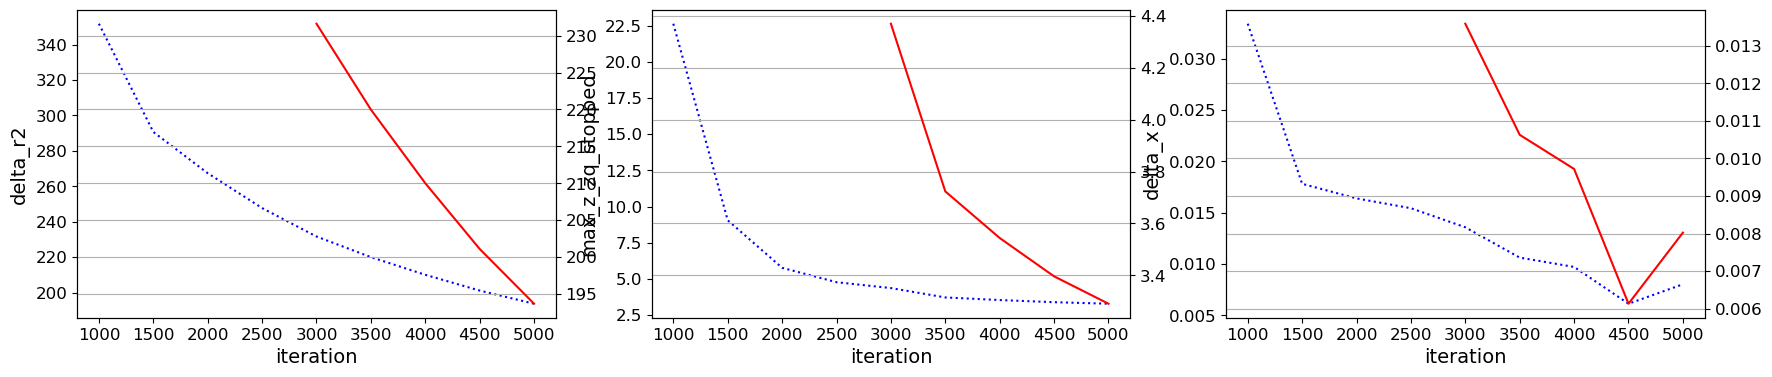

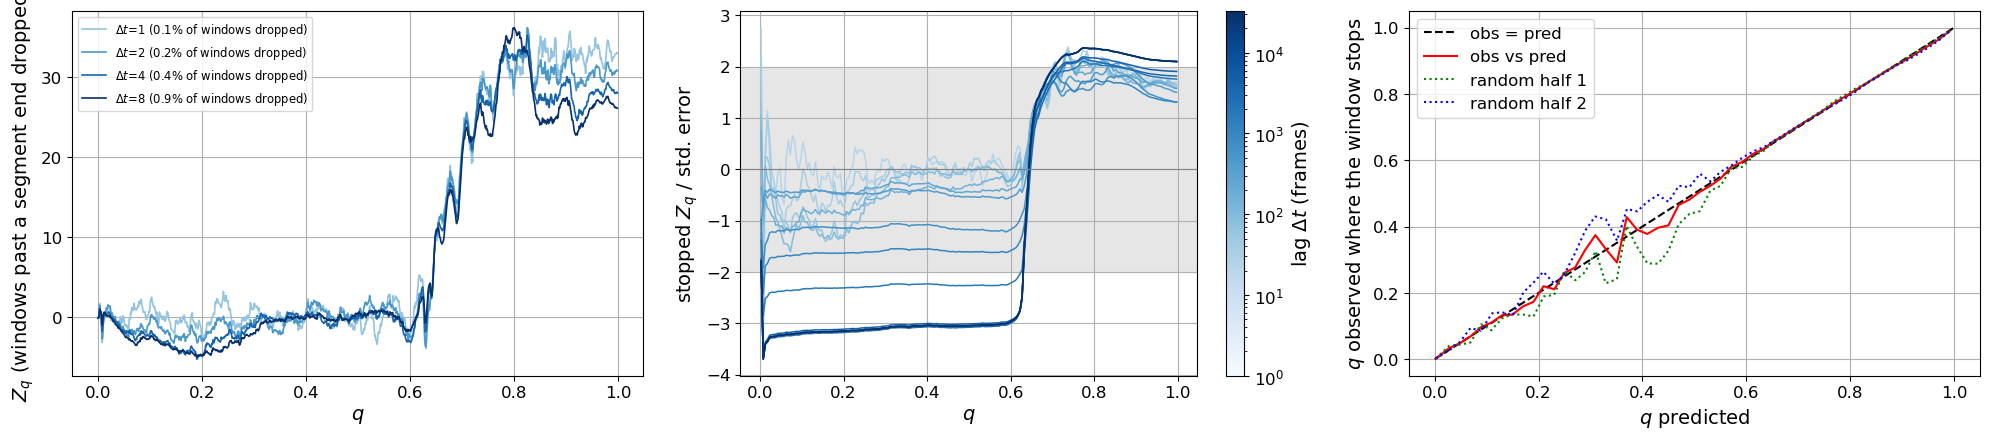

seed 0, 11000 iterations (main: envelope 0.01, gamma 0.1) | fit/shooting at plateau points: 0.653/0.639 0.690/0.664 0.706/0.698 0.759/0.747


In [ ]:
import seed_runs

CONTINUE = False                    # start every seed from the saved fit
ADD_DIAG = False                   # add y + x as a CV
MAX_ITER = 15000                   # iterations per seed (after the warm-up)
SEEDS = [0,1,2]
CHUNK = 5000                       # iterations between shown and saved plots
ENVELOPE = 0.01                    # envelope_scale (library default, as in the original fit)
GAMMA = 0.1                        # regularization strength
WARMUP_ITER = 1000                    # optional warm-up (0 = off)
WARMUP_ENVELOPE = 1
WARMUP_GAMMA = GAMMA
WARMUP_CV = None                   # None: random CV; 0: y, 1: x, 2: y + x
PLOTS = ('metrics', 'tis', 'feps', 'obs_pred', )         # add 'feps', 'obs_pred' if GPU memory allows (20.8M frames)
OUT = f'{FIG}/nb_brownian_staple/{"diag" if ADD_DIAG else "yx"}{"_cont" if CONTINUE else ""}'

cvs = [y_pos, x_pos] + ([y_pos + x_pos] if ADD_DIAG else [])
X_gpu = cp.asarray(np.column_stack(cvs))

def make_q():
    q = optimalrcs.CommittorNE(
        boundary0=boundary0,           # state A
        boundary1=boundary1,           # state B
        i_traj=i_traj,                 # path
        t_traj=t_traj,                 # MD step
        path_weights=path_weights,
        group_traj=group_traj,
        seed_r=r_saved if (CONTINUE and r_saved is not None) else None,
    )
    q.set_fixed_traj_length_trap(boundary0 | boundary1, 2 ** 16)
    return q

# progress: the fit at the four plateau points checked by shooting with the toytis engine
SHOOT = [((0.50, 0.25), 0.639), ((0.55, 0.10), 0.664), ((0.62, 0.15), 0.698), ((0.70, 0.15), 0.747)]
free_np = ~(boundary0 | boundary1)
NEAR = [cp.asarray(np.flatnonzero(free_np & ((y_pos - y0) ** 2 + (x_pos - x0) ** 2 < 0.01 ** 2))) for (y0, x0), _ in SHOOT]
def report(q):
    return '| fit/shooting at plateau points: ' + ' '.join(
        f'{float(q.r_traj[idx].mean()):.3f}/{qs:.3f}' for idx, (_, qs) in zip(NEAR, SHOOT))

# after every chunk: q on (y, x) next to the exact committor and fit - exact, on the effective potential
# (the maps of section 4; ref, q_exact, V and lev are used there as well)
ref = np.load(f'{FIG}/z_brownian/committor_reference_h0.001.npz')
f_ref = RegularGridInterpolator((ref['y'], ref['x']), ref['q'], bounds_error=False, fill_value=None)
q_exact = np.clip(f_ref(np.c_[y_pos, x_pos]), 0, 1)
V = ref['V_eff']; inside = (ref['y'] >= -0.01) & (ref['y'] <= 0.91)
lev = np.linspace(np.percentile(V[inside], 1), np.percentile(V[inside], 92), 14)
q_map = seed_runs.committor_map(
    [seed_runs.plane(y_pos, np.linspace(0.05, 0.85, 81), 'order parameter y', x_pos, np.linspace(-0.01, 0.31, 33), 'x',
                     contours=(ref['y'][inside], ref['x'], V[inside], lev))],
    mask=free_np, q_ref=q_exact)

results, q = seed_runs.run_seeds(
    optimalrcs, make_q,
    comp_y=lambda: X_gpu[:, np.random.randint(X_gpu.shape[1])],
    fit_kw=dict(ny=6, print_step=500, min_delta_x=1e-6, lazy_basis=True, save_min_metric='max_z_zq_stopped',
                metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed')),
    seeds=SEEDS, max_iter=MAX_ITER, chunk=CHUNK, out_dir=OUT, envelope=ENVELOPE, gamma=GAMMA,
    warmup_iter=WARMUP_ITER, warmup_envelope=WARMUP_ENVELOPE, warmup_gamma=WARMUP_GAMMA,
    warmup_comp_y=None if WARMUP_CV is None else (lambda: X_gpu[:, WARMUP_CV]),
    plots=PLOTS, plot_options=dict(metrics=['delta_r2', 'max_z_zq_stopped', 'delta_x']),
    extra_plot={'q_y_x': q_map},
    report=report,
)

## 4. Comparison with the Exact Committor

The exact committor of this dynamics (finite-volume solution of the backward equation, `figures/z_brownian/committor_reference.py`, for A: y ≤ 0.05, B: y ≥ 0.85, absorption checked every step), confirmed by shooting with the toytis engine at four plateau points (1200 trajectories each). Maps show the mean q per (y, x) bin with at least 20 frames; grey: contours of the effective potential; dashed: q = 0.1, 0.5, 0.9.

In [ ]:
r = cp.asnumpy(q.r_traj)          # ref, q_exact, V and lev: loaded in section 3
free = ~(boundary0 | boundary1)

ey, ex = np.linspace(0.05, 0.85, 81), np.linspace(-0.01, 0.31, 33)
cy, cx = (ey[1:] + ey[:-1]) / 2, (ex[1:] + ex[:-1]) / 2
n_bin = np.histogram2d(y_pos[free], x_pos[free], bins=(ey, ex))[0]
def bin_mean(val):
    s = np.histogram2d(y_pos[free], x_pos[free], bins=(ey, ex), weights=val[free])[0]
    return np.where(n_bin >= 20, s / np.maximum(n_bin, 1), np.nan)
Q_fit, Q_ex = bin_mean(r), bin_mean(q_exact)
Q_orig = bin_mean(r_saved) if r_saved is not None else None
trans = (Q_ex > 0.05) & (Q_ex < 0.95)
rms = lambda D: np.sqrt(np.nanmean(D[trans] ** 2))
print(f'per bin, 0.05 < q_exact < 0.95: RMS(fit - exact) {rms(Q_fit - Q_ex):.4f}'
      + (f', original fit {rms(Q_orig - Q_ex):.4f}' if Q_orig is not None else ''))

# plateau points: engine shooting (figures/z_brownian/shoot_engine.py)
shoot = [((0.50, 0.25), 0.639, 0.014), ((0.55, 0.10), 0.664, 0.014), ((0.62, 0.15), 0.698, 0.013), ((0.70, 0.15), 0.747, 0.013)]
print('point (y, x)   shooting        fit     original fit')
for (y0, x0), qs, se in shoot:
    near = free & ((y_pos - y0) ** 2 + (x_pos - x0) ** 2 < 0.01 ** 2)
    print(f'({y0:.2f}, {x0:.2f})   {qs:.3f} +- {se:.3f}   {r[near].mean():.3f}'
          + (f'    {r_saved[near].mean():.3f}' if r_saved is not None else ''))

panels = [(Q_fit, 'this fit', 'coolwarm', (0, 1)), (Q_ex, 'exact committor', 'coolwarm', (0, 1)),
          (Q_fit - Q_ex, 'this fit - exact', 'PuOr', (-0.15, 0.15))]
if Q_orig is not None:
    panels.append((Q_orig - Q_ex, 'original fit (10000 it.) - exact', 'PuOr', (-0.15, 0.15)))
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for ax, (M, title, cmap, (vmin, vmax)) in zip(axes.ravel(), panels):
    im = ax.imshow(M.T, origin='lower', extent=[ey[0], ey[-1], ex[0], ex[-1]], aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax)
    ax.contour(ref['y'][inside], ref['x'], V[inside].T, levels=lev, colors='0.4', linewidths=0.5)
    if vmin == 0:
        ax.contour(cy, cx, np.nan_to_num(M, nan=0.5).T, levels=[0.1, 0.5, 0.9], colors='k', linewidths=1, linestyles='--')
    ax.set(title=title, xlabel='order parameter y', ylabel='x', xlim=(0.04, 0.86), ylim=(-0.01, 0.31))
    fig.colorbar(im, ax=ax)
for ax in axes.ravel()[len(panels):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Save Results

Saves the committor with the frames, in the same format as the original fit's `committor.npz`, so a later run can continue from it (set `FIT_NPZ` to the new file).

In [ ]:
OUT_NPZ = f'{FIG}/istarz_br_g10/committor_long{"_diag" if ADD_DIAG else ""}.npz'
np.savez(OUT_NPZ, r=r, lam=lam, X_all=X_all, i_traj=i_traj, t_traj=t_traj, path_weights=path_weights,
         boundary0=boundary0, boundary1=boundary1)
print(f'saved {OUT_NPZ}')